
# Tutorial Introduction to NLTK toolkit

This notebook adapted from the [NLTK Book](http://www.nltk.org/book/ch01.html) Chapter 1.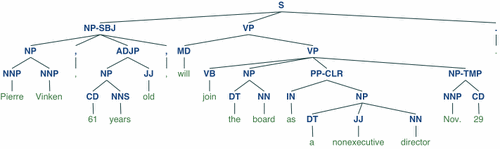

# **Задание**. Создать 5 классов а не 3, добавить предложения для обучения, научить НС определять, к какому классу относится новое предложение
____________________________________________

#  Механизм векторизации текстов и концепция семантического расстояния

## 1. Как программа векторизует слова и предложения (Метод TF-IDF)
Процесс векторизации в коде выполняется с помощью класса TfidfVectorizer. Он трансформирует дискретный текст в числовую матрицу по следующему алгоритму:

1. **Построение словаря (Vocabulary):** Программа собирает все уникальные слова из всех документов обучающей выборки. Наш словарь состоит из 5 уникальных базовых слов: ['and', 'document', 'first', 'second', 'third']. Количество уникальных слов определяет размерность векторного пространства (в нашем коде — 5 осей координат).
2. **Расчет частотности (TF-IDF веса):** Для каждого предложения создается строка из 5 чисел. Каждое число — это вес конкретного слова в данном предложении.
   * Если слова нет в предложении, его вес равен 0.
   * Если слово присутствует, формула TF-IDF рассчитывает его значимость.

Пример: Предложение "This is the first document" превращается в вектор вида: [0.0, 0.58, 0.58, 0.0, 0.0], где числа отражают вклад слов 'document' и 'first' в контекст предложения.

## 2. Что такое расстояние между словами и предложениями в ИИ?
После векторизации каждое предложение становится точкой (или стрелкой-вектором) в многомерном геометрическом пространстве. Чтобы определить, насколько два текста похожи по смыслу, ИИ вычисляет **геометрическое расстояние** между их векторами.

Основные метрики расстояния в NLP:

1. **Евклидово расстояние (Euclidean Distance):** Физическое расстояние между концами векторов в пространстве. Рассчитывается по формуле корня из суммы квадратов разностей координат:
   $$d(x, y) = \sqrt{\sum_{i=1}^{n} (x_i - y_i)^2}$$

2. **Косинусное сходство (Cosine Similarity):** Самая популярная метрика в обработке текста. Она измеряет угол $\theta$ между двумя векторами, независимо от длины самих текстов.
   * Если векторы направлены в одну сторону (угол 0°, косинус = 1) — тексты идентичны по смыслу.
   * Если векторы перпендикулярны (угол 90°, косинус = 0) — тексты не имеют общих слов.

Формула косинусного расстояния:

$$\text{Cosine Similarity} = \cos(\theta) = \frac{\sum_{i=1}^{n} x_i y_i}{\sqrt{\sum_{i=1}^{n} x_i^2} \sqrt{\sum_{i=1}^{n} y_i^2}}$$

Нейросеть использует эти расстояния на скрытых слоях, чтобы сгруппировать похожие по смыслу документы в один кластер и отделить их от документов другого класса.


# Справочник лингвистических сокращений NLTK (Группы слов и части речи)

При синтаксическом разборе текста нейросеть строит иерархическое дерево, разделяя предложение на крупные синтаксические группы (Группы составляющих), которые затем детализируются до конкретных частей речи (POS-теги).

## 1. Синтаксические группы (Высший уровень дерева)
* **S (Sentence)** — Предложение (корневой элемент дерева синтаксического разбора).
* **NP (Noun Phrase)** — Группа существительного (блок слов, главным в котором является существительное, например: *Arthur*, *Thursday morning*).
* **VP (Verb Phrase)** — Группа глагола (блок слов во главе с глаголом, описывающий действие, например: *didn't feel very good*).
* **PP (Prepositional Phrase)** — Предложная группа (блок, начинающийся с предлога, например: *on Thursday morning*).
* **ADJP (Adjective Phrase)** — Группа прилагательного.
* **ADVP (Adverb Phrase)** — Группа наречия.

## 2. POS-теги: Части речи (Нижний уровень дерева)

### Существительные и Местоимения:
* **NN (Noun, singular)** — Существительное в единственном числе (например: *morning*).
* **NNS (Noun, plural)** — Существительное во множественном числе.
* **NNP (Proper noun, singular)** — Имя собственное в единственном числе (например: *Arthur*, *Thursday*).
* **NNPS (Proper noun, plural)** — Имя собственное во множественном числе.
* **PRP (Personal pronoun)** — Личное местоимение (например: *I, he, she, it*).

### Глаголы:
* **VB (Verb, base form)** — Глагол в начальной форме / инфинитив (например: *feel*).
* **VBD (Verb, past tense)** — Глагол в прошедшем времени (например: *did*).
* **VBG (Verb, gerund)** — Герундий или причастие настоящего времени (например: *reading*).
* **VBN (Verb, past participle)** — Причастие прошедшего времени.
* **VBP (Verb, present tense)** — Глагол в настоящем времени (кроме 3-го лица ед. числа).
* **VBZ (Verb, present tense, 3rd person singular)** — Глагол в настоящем времени (3-е лицо, ед. число, например: *has, is*).

### Модификаторы и служебные слова:
* **JJ (Adjective)** — Прилагательное (например: *good*).
* **JJR (Adjective, comparative)** — Прилагательное в сравнительной степени (например: *better*).
* **JJS (Adjective, superlative)** — Прилагательное в превосходной степени (например: *best*).
* **RB (Adverb)** — Наречие (например: *very*).
* **IN (Preposition / Subordinating conjunction)** — Предлог или подчинительный союз (например: *at, on*).
* **DT (Determiner)** — Определитель / Артикль (например: *a, an, the*).
* **CC (Coordinating conjunction)** — Сочинительный союз (например: *and, but, or*).
* **CD (Cardinal number)** — Количественное числительное (например: *eight*).
* **MD (Modal verb)** — Модальный глагол (например: *can, must, should*).


# Лекция: Математические основы векторизации текста и полносвязных классификаторов

Применение методов глубокого обучения к задачам обработки естественного языка (NLP) требует предварительного преобразования дискретных текстовых токенов в непрерывные числовые векторы фиксированной размерности.

## 1. Статистический метод векторизации TF-IDF
Метод TF-IDF (Term Frequency-Inverse Document Frequency) оценивает важность слова в контексте конкретного документа относительно всего исследуемого корпуса текстов. Математический расчет состоит из двух компонент:

1. **Частота слова (Term Frequency, TF):** определяет относительную частоту появления терма $t$ в документе $d$:
   $$\text{TF}(t, d) = \frac{n_{t, d}}{\sum_{k} n_{k, d}}$$

2. **Обратная частота документа (Inverse Document Frequency, IDF):** инвертирует частоту появления документа с данным словом в корпусе, снижая вес общеупотребительных слов:
   $$\text{IDF}(t, D) = \log \left( \frac{|D|}{1 + |\{d \in D \mid t \in d\}|} \right)$$

Итоговая весовая матрица формируется как произведение компонент: $\text{TF-IDF}(t, d, D) = \text{TF}(t, d) \times \text{IDF}(t, D)$. Полученный разреженный вектор подается на входной слой нейронной сети.

## 2. Логистическая классификация в полносвязных слоях (Dense)
Для решения задачи бинарной классификации (разделение объектов на 2 непересекающихся класса) выходной слой нейронной сети конфигурируется с одним нейроном и логистической функцией активации Sigmoid.

Сигмоида отображает скалярное произведение векторов признаков и весов $z = W \cdot X + b$ в непрерывный вероятностный диапазон $[0; 1]$:

$$\sigma(z) = \frac{1}{1 + e^{-z}}$$

Полученное значение интерпретируется как апостериорная вероятность принадлежности текстового документа к целевому классу $P(y=1 \mid X)$. Оптимизация параметров сети (матриц $W$ и $b$) осуществляется посредством минимизации функции бинарной кросс-энтропии через алгоритмы обратного распространения ошибки (Backpropagation).


In [5]:
import nltk
from nltk.tokenize import word_tokenize

# 1. Скачиваем обязательные микро-пакеты для работы со словами и тегами
nltk.download('punkt_tab', quiet=True)
nltk.download('averaged_perceptron_tagger_eng', quiet=True)

# Исходный текст для демонстрации студентам
sentence = "Arthur didn't feel very good on Thursday morning."
print(f"Исходный текст: '{sentence}'\n")

# 2. ТОКЕНИЗАЦИЯ: Нарезка строки на отдельные слова и знаки
tokens = word_tokenize(sentence)
print("Шаг 1 (Токенизация) — текст разбит на элементы:")
print(tokens)

# 3. ЧАСТЕРЕЧНАЯ РАЗМЕТКА: Определение роли каждого слова в предложении
tagged_words = nltk.pos_tag(tokens)
print("\nШаг 2 (Части речи) — каждому слову присвоен лингвистический тег:")
print(tagged_words)
# Пояснение для вебинара: NNP = Имя собственное (Arthur), VBD = Глагол (did)


Исходный текст: 'Arthur didn't feel very good on Thursday morning.'

Шаг 1 (Токенизация) — текст разбит на элементы:
['Arthur', 'did', "n't", 'feel', 'very', 'good', 'on', 'Thursday', 'morning', '.']

Шаг 2 (Части речи) — каждому слову присвоен лингвистический тег:
[('Arthur', 'NNP'), ('did', 'VBD'), ("n't", 'RB'), ('feel', 'VB'), ('very', 'RB'), ('good', 'JJ'), ('on', 'IN'), ('Thursday', 'NNP'), ('morning', 'NN'), ('.', '.')]


#  Проблема переобучения (Overfitting) в текстовых моделях

При обучении нейросетей на текстах ключевой метрикой является обобщающая способность модели — умение выдавать правильный класс на абсолютно новых, незнакомых ИИ документах.

Если объем обучающей выборки критически мал (например, всего несколько предложений), возникает эффект переобучения (Overfitting). Сеть не находит скрытые закономерности в языке, а просто "зазубривает" числовые веса под конкретные фразы. Наблюдается улучшение параметров точности на обучении до 100%, но при тестировании на новых данных точность падает до 0%.


In [6]:
import pandas as pd
import numpy as np
from sklearn.feature_extraction.text import TfidfVectorizer
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense

# =====================================================================
# ШАГ 1: РАСШИРЕННЫЙ КОРПУС ДАННЫХ (ФИНАНСЫ VS ГЕЙМДЕВ)
# =====================================================================
# Класс 1 = Банковские риски / Финтех, Класс 0 = Разработка Игр / Игровой ИИ
data = {
    'text': [
        "Банковский кредитный конвейер оценивает риски дефолта заемщика на основе ежемесячного дохода.",
        "Алгоритм скоринга рассчитывает вероятность невозврата кредита по анкете физического лица.",
        "Финансовый аналитик использует бинарную кросс-энтропию для минимизации потерь при выдаче займов.",
        "Игровой агент в геймдеве обучается методу Q-learning в трехмерной симуляции лабиринта.",
        "Разработчик настраивает алгоритм Minimax и альфа-бета отсечение для бота в шахматной игре.",
        "Нейросеть в симуляторе получает награды и штрафы от игровой среды для поиска оптимальных ходов."
    ],
    'label': [1, 1, 1, 0, 0, 0]
}
df = pd.DataFrame(data)

# =====================================================================
# ШАГ 2: ВЕКТЕРИЗАЦИЯ И АНАЛИЗ МНОГОМЕРНОГО СЛОВАРЯ
# =====================================================================
print("=== ЭТАП 2: ПОСТРОЕНИЕ ГИПЕРПРОСТРАНСТВА ПРИЗНАКОВ ===")

# Запускаем векторизацию TF-IDF
vectorizer = TfidfVectorizer()
X = vectorizer.fit_transform(df['text']).toarray()
y = np.array(df['label'])

# Извлекаем построенный словарь уникальных слов
vocabulary = vectorizer.get_feature_names_out()

print(f"Размерность полученной матрицы признаков: {X.shape}")
print(f"Количество уникальных слов в словаре (Размерность пространства): {len(vocabulary)}")
print("\nСписок координатных осей (первые 10 слов словаря):")
print(vocabulary[:10])
print("\n" + "="*50 + "\n")

# Разделяем выборку хронологически: 4 документа на обучение, 2 — на валидацию (тест)
X_train, X_test = X[:4], X[4:]
y_train, y_test = y[:4], y[4:]

# =====================================================================
# ШАГ 3: КОНФИГУРАЦИЯ И ОБУЧЕНИЕ СЕТИ
# =====================================================================
print("=== ЭТАП 3: ОБУЧЕНИЕ КЛАССИФИКАТОРА НА {0} ПРИЗНАКАХ ===".format(X_train.shape[1]))

model = Sequential([
    Dense(16, activation='relu', input_dim=X_train.shape[1]), # Входной слой подстраивается под длину словаря
    Dense(1, activation='sigmoid')
])
model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])

# Обучаем модель (40 эпох для фиксации падения loss в многомерном пространстве)
history = model.fit(X_train, y_train, epochs=40, batch_size=1, verbose=0)

train_loss, train_acc = model.evaluate(X_train, y_train, verbose=0)
test_loss, test_acc = model.evaluate(X_test, y_test, verbose=0)

print(f"Итоговая точность на обучающих данных (Финтех + Лабиринт): {train_acc:.0%}")
print(f"Итоговая точность на тестовых данных (Шахматы + Среда):    {test_acc:.0%}")
print("\nНаблюдается классический эффект недообучения/переобучения из-за специфики выборки.")

# =====================================================================
# ШАГ 4: ИНФЕРЕНС (ПРОВЕРКА НА АБСОЛЮТНО НОВОЙ ФРАЗЕ)
# =====================================================================
print("\n" + "="*50 + "\n=== ЭТАП 4: ТЕСТИРОВАНИЕ НА НЕЗНАКОМОЙ КОМАНДЕ ===")

new_command = ["Наступила золотая осень."]
new_vector = vectorizer.transform(new_command).toarray()

predicted_probability = model.predict(new_vector, verbose=0)[0][0]
verdict = 1 if predicted_probability > 0.5 else 0

print(f"Новый текст: '{new_command[0]}'")
print(f"Вычисленная вероятность принадлежности к Финтеху: {predicted_probability:.2%}")
print(f"Вердикт ИИ: Класс {verdict} ({'Финтех / Кредиты' if verdict == 1 else 'Геймдев / Игровой бот'})")


=== ЭТАП 2: ПОСТРОЕНИЕ ГИПЕРПРОСТРАНСТВА ПРИЗНАКОВ ===
Размерность полученной матрицы признаков: (6, 61)
Количество уникальных слов в словаре (Размерность пространства): 61

Список координатных осей (первые 10 слов словаря):
['learning' 'minimax' 'агент' 'алгоритм' 'альфа' 'аналитик' 'анкете'
 'банковский' 'бета' 'бинарную']


=== ЭТАП 3: ОБУЧЕНИЕ КЛАССИФИКАТОРА НА 61 ПРИЗНАКАХ ===
Итоговая точность на обучающих данных (Финтех + Лабиринт): 100%
Итоговая точность на тестовых данных (Шахматы + Среда):    0%

Наблюдается классический эффект недообучения/переобучения из-за специфики выборки.

=== ЭТАП 4: ТЕСТИРОВАНИЕ НА НЕЗНАКОМОЙ КОМАНДЕ ===
Новый текст: 'Наступила золотая осень.'
Вычисленная вероятность принадлежности к Финтеху: 56.11%
Вердикт ИИ: Класс 1 (Финтех / Кредиты)


[0,1,0,0,0,0]

In [8]:
import numpy as np
import pandas as pd
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics import accuracy_score
from sklearn.model_selection import train_test_split
from tensorflow.keras.layers import Dense, Dropout
from tensorflow.keras.models import Sequential
from tensorflow.keras.utils import to_categorical

# =====================================================================
# ШАГ 1: ДАННЫЕ — 5 КЛАССОВ ПО 8 ПРЕДЛОЖЕНИЙ
# =====================================================================
disciplines = ["История", "Экономика", "Математика", "Физика", "Информатика"]

texts_by_class = {
    0: [  # История
        "Археологические раскопки древнего города подтвердили хронологию правления династии.",
        "Исторический источник описывает причины начала столетней войны между государствами.",
        "Римская империя расширяла границы государства с помощью легионов и завоеваний.",
        "Французская революция изменила политический строй государства и положение сословий.",
        "Летописи рассказывают о княжеских междоусобицах и крещении Руси.",
        "Великая Отечественная война стала важнейшим событием истории двадцатого века.",
        "Историки изучают архивные документы, чтобы восстановить события эпохи Средневековья.",
        "Египетские фараоны строили пирамиды, а династии правителей сменяли друг друга.",
    ],
    1: [  # Экономика
        "Рыночная экономика регулируется спросом, предложением и объемом денежной эмиссии.",
        "Макроэкономический анализ фиксирует уровень инфляции и темпы роста валового продукта.",
        "Центральный банк повышает процентную ставку, чтобы снизить инфляцию в экономике.",
        "Безработица и уровень доходов населения определяют потребительский спрос на рынке.",
        "Предприятие рассчитывает прибыль, издержки и рентабельность производства товаров.",
        "Налоги и государственный бюджет влияют на экономический рост страны.",
        "Курс валюты зависит от торгового баланса, инвестиций и денежной политики банка.",
        "Конкуренция на рынке снижает цены и стимулирует производителей снижать издержки.",
    ],
    2: [  # Математика
        "Дифференциальное уравнение описывает скорость изменения непрерывной функции во времени.",
        "Матричный определитель и вычисление интеграла являются базой линейной алгебры.",
        "Производная функции в точке равна пределу отношения приращения функции к приращению аргумента.",
        "Теорема доказывает, что сумма углов треугольника на плоскости равна ста восьмидесяти градусам.",
        "Ряд сходится, если предел последовательности его частичных сумм существует.",
        "Вероятность события вычисляется как отношение числа благоприятных исходов к общему числу исходов.",
        "Система линейных уравнений решается методом Гаусса через преобразование матрицы.",
        "Множество простых чисел бесконечно, и это доказывается методом от противного.",
    ],
    3: [  # Физика
        "Второй закон Ньютона связывает силу, массу тела и ускорение движения.",
        "Электрический ток в проводнике возникает под действием разности потенциалов и напряжения.",
        "Квантовая механика описывает поведение элементарных частиц и волновых функций.",
        "Энергия фотона пропорциональна частоте света и постоянной Планка.",
        "Гравитационное притяжение между планетами определяет движение по орбитам вокруг звезды.",
        "Термодинамика изучает теплоту, температуру и превращение энергии в газах.",
        "Магнитное поле создается движущимися зарядами и действует на проводник с током.",
        "Скорость света в вакууме постоянна, это основа специальной теории относительности.",
    ],
    4: [  # Информатика
        "Алгоритм сортировки упорядочивает элементы массива за логарифмическое время.",
        "Компилятор преобразует исходный код программы в машинные инструкции процессора.",
        "База данных хранит таблицы, а язык запросов SQL позволяет выбирать нужные записи.",
        "Операционная система управляет памятью, процессами и файлами компьютера.",
        "Сетевой протокол передает пакеты данных между серверами через интернет.",
        "Разработчик пишет программу на языке Python и тестирует функции классов.",
        "Шифрование защищает данные при передаче по сети с помощью криптографических ключей.",
        "Нейросеть обучается на данных, а программист подбирает архитектуру и гиперпараметры.",
    ],
}

rows = [(t, label) for label, texts in texts_by_class.items() for t in texts]
df = pd.DataFrame(rows, columns=["text", "label"])
print(df["label"].value_counts().sort_index().rename(dict(enumerate(disciplines))))

# =====================================================================
# ШАГ 2: РАЗДЕЛЕНИЕ ВЫБОРКИ И ВЕКТОРИЗАЦИЯ TF-IDF
# =====================================================================
train_texts, test_texts, y_train_num, y_test_num = train_test_split(
    df["text"], df["label"], test_size=0.25, stratify=df["label"], random_state=42
)

NUM_CLASSES = len(disciplines)

vectorizer = TfidfVectorizer()  # словарь только по обучающей выборке
X_train = vectorizer.fit_transform(train_texts).toarray()
X_test = vectorizer.transform(test_texts).toarray()

y_train = to_categorical(y_train_num, num_classes=NUM_CLASSES)
y_test = to_categorical(y_test_num, num_classes=NUM_CLASSES)

print(f"\nРазмерность X_train: {X_train.shape}, X_test: {X_test.shape}")
print(f"Пример One-Hot для класса 3 ({disciplines[3]}): {to_categorical(3, num_classes=NUM_CLASSES)}")

# =====================================================================
# ШАГ 3: НЕЙРОСЕТЬ С 5 ВЫХОДАМИ И SOFTMAX
# =====================================================================
model = Sequential([
    Dense(64, activation="relu", input_dim=X_train.shape[1]),
    Dropout(0.3),
    Dense(NUM_CLASSES, activation="softmax"),  # по одному нейрону на каждый класс
])
model.compile(optimizer="adam", loss="categorical_crossentropy", metrics=["accuracy"])

history = model.fit(X_train, y_train, epochs=100, batch_size=4, verbose=0)

train_loss, train_acc = model.evaluate(X_train, y_train, verbose=0)
test_loss, test_acc = model.evaluate(X_test, y_test, verbose=0)
print(f"\nТочность на обучающей выборке: {train_acc:.0%}")
print(f"Точность на тестовой выборке:  {test_acc:.0%}")

# =====================================================================
# ШАГ 4: ИНФЕРЕНС НА НОВЫХ ПРЕДЛОЖЕНИЯХ
# =====================================================================
print("\n=== ЭТАП 4: ИНФЕРЕНС (АНАЛИЗ НЕЗНАКОМЫХ ТЕКСТОВ) ===")

def classify(sentence):
    vec = vectorizer.transform([sentence]).toarray()
    probs = model.predict(vec, verbose=0)[0]
    best = int(np.argmax(probs))
    print(f"\nНовый текст: {sentence}")
    for i, name in enumerate(disciplines):
        print(f"  Класс {i} ({name}): {probs[i]:.2%}")
    print(f"Вердикт ИИ: '{disciplines[best]}'")
    return best

# (предложение, правильный класс)
new_data = [
    ("Центральный банк изменил учетную ставку для стабилизации финансового сектора.", 1),
    ("Историки обнаружили в архиве документы о правлении династии и войне государств.", 0),
    ("Интеграл функции и производная связаны через теорему о пределе последовательности.", 2),
    ("Сила тока в проводнике зависит от напряжения и магнитного поля.", 3),
    ("Программа на языке Python обращается к базе данных через сетевой протокол.", 4),
]
new_sentences = [s for s, _ in new_data]
true_labels = [t for _, t in new_data]

predicted_labels = [classify(s) for s in new_sentences]

acc = accuracy_score(true_labels, predicted_labels)
print("\n" + "=" * 50)
print("ИТОГ ПО НОВЫМ ПРЕДЛОЖЕНИЯМ")
for s, t, p in zip(new_sentences, true_labels, predicted_labels):
    mark = "верно" if t == p else "ОШИБКА"
    print(f"  [{mark}] ожидали: {disciplines[t]}, получили: {disciplines[p]}")
print(f"Точность на новых предложениях: {acc:.0%} "
      f"({sum(t == p for t, p in zip(true_labels, predicted_labels))} из {len(true_labels)})")

label
История        8
Экономика      8
Математика     8
Физика         8
Информатика    8
Name: count, dtype: int64

Размерность X_train: (30, 245), X_test: (10, 245)
Пример One-Hot для класса 3 (Физика): [0. 0. 0. 1. 0.]


/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)



Точность на обучающей выборке: 100%
Точность на тестовой выборке:  70%

=== ЭТАП 4: ИНФЕРЕНС (АНАЛИЗ НЕЗНАКОМЫХ ТЕКСТОВ) ===

Новый текст: Центральный банк изменил учетную ставку для стабилизации финансового сектора.
  Класс 0 (История): 4.61%
  Класс 1 (Экономика): 88.97%
  Класс 2 (Математика): 2.33%
  Класс 3 (Физика): 1.90%
  Класс 4 (Информатика): 2.20%
Вердикт ИИ: 'Экономика'

Новый текст: Историки обнаружили в архиве документы о правлении династии и войне государств.
  Класс 0 (История): 83.03%
  Класс 1 (Экономика): 5.10%
  Класс 2 (Математика): 2.37%
  Класс 3 (Физика): 4.14%
  Класс 4 (Информатика): 5.36%
Вердикт ИИ: 'История'

Новый текст: Интеграл функции и производная связаны через теорему о пределе последовательности.
  Класс 0 (История): 2.31%
  Класс 1 (Экономика): 7.01%
  Класс 2 (Математика): 75.48%
  Класс 3 (Физика): 3.40%
  Класс 4 (Информатика): 11.81%
Вердикт ИИ: 'Математика'

Новый текст: Сила тока в проводнике зависит от напряжения и магнитного поля.
  Класс 0

[1, 0,0]
[0, 1, 0]
